# Rejection-sampler cost against signal-to-noise

This notebook measures how the cost of the rejection sampler grows with the
signal-to-noise of the data, for the standard RV parameterization and the standard and
Thiele-Innes Gaia astrometry parameterizations, and makes the figure for the
performance appendix of the paper.

The cost of getting $X$ effective samples splits into two factors,
$$ t(X) \approx X \, \frac{J}{J_{\rm eff}} \, \frac{1}{R(N)} \quad , $$
where $R(N)$ is the number of prior samples evaluated per second, which depends on the
number of observations $N$ and the device but not on the data values, and
$J_{\rm eff}/J \approx e^{-H}$ (Case study 3), where $H$ is the information over the
sampled parameters. For informative data, each posterior width shrinks like
$1/\rho$, where $\rho$ is the total signal-to-noise ratio of the orbit over all $N$
observations (not the per-visit signal-to-noise ratio), so we expect
$J_{\rm eff}/J \propto \rho^{-d}$ with $d$ the number of sampled parameters: 4 for
the standard RV parameterization ($P$, $e$, phase, $\omega$), 6 for the standard
Gaia parameterization ($P$, $e$, phase, $\omega$, $\Omega$, $\cos i$), and 3 for the
Thiele-Innes parameterization ($P$, $e$, phase), which replaces $a_0$ and the three
orientation angles with four linear constants. If that is right, curves for different
$N$ fall on top of each other when plotted against $\rho$ in the informative regime.

The parallax is a linear parameter, but the default Gaia priors on $a_0$, the
Thiele-Innes constants and the proper motion have widths that scale with it, so by
default harv samples it. Here we compute those widths from a fixed, catalog-like
parallax instead (`scale_parallax`), so the parallax is marginalized. A spot check
measures how much sampling it would cost.

Run this on the benchmark workstation with a GPU (see `scripts/README.md`). On Linux,
the first cell pins the process to one CPU core, so the CPU throughput is for one core.
A full run takes a few hours; set `J_MAX = 10**6` for a quick check.

The results are saved to `data/benchmarks-ess.ecsv`. If that file exists, the notebook
skips the measurements and only makes the fits and the figure, so delete the file to
rerun them.

In [1]:
import os

# One CPU core for the CPU throughput numbers. This has to happen before numpy or jax
# are imported.
os.environ["XLA_FLAGS"] = (
    "--xla_cpu_multi_thread_eigen=false intra_op_parallelism_threads=1"
)
for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[var] = "1"
if hasattr(os, "sched_setaffinity"):  # Linux only
    os.sched_setaffinity(0, {min(os.sched_getaffinity(0))})

import jax

# Enable float64 before importing harv:
jax.config.update("jax_enable_x64", True)

In [2]:
import time
import warnings
from pathlib import Path

import astropy.constants as const
import astropy.table as at
import astropy.units as u
import harv
import harv.models as hm
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
from harv.models.parameterizations import ThieleInnesGaiaAstrometry
from harv.simulate import simulate_gaia_epoch_astrometry, simulate_rv_sb1_data
from unxt import Q

%matplotlib inline
print(f"harv {harv.__version__}, jax {jax.__version__}")
print(jax.devices())

# The sampler warns when J_eff < 3. Here that is expected for the largest rho values.
warnings.filterwarnings("ignore", message="Under-resolved rejection run")

harv 0.0.2.dev258+g9eadbbfe8, jax 0.11.2
[CpuDevice(id=0)]


In [3]:
repo_path = Path("..").resolve()
figure_path = repo_path / "paper" / "figures"
data_path = repo_path / "data"
figure_path.mkdir(exist_ok=True)
data_path.mkdir(exist_ok=True)

# The sweep and throughput results are saved here; delete the file to rerun them.
results_path = data_path / "benchmarks-ess.ecsv"
run_benchmarks = not results_path.exists()

J_MAX = 10**9  # largest prior library per source
ESS_MIN = 128  # J_eff needed to call a cell resolved
N_SEEDS = 3  # realizations of the observing times and noise per cell
RHO_VALUES = np.geomspace(10**-0.5, 1000.0, 15)  # total SNR, 0.25 dex apart
X = ESS_MIN  # quote the cost of the J_eff that the sweep measures

N_VALUES = {"rv": (3, 6, 12), "gaia": (40, 250), "gaia_ti": (40, 250)}
KINDS = tuple(N_VALUES)
D_NL = {"rv": 4, "gaia": 6, "gaia_ti": 3}

## Priors and simulated data

We use the prior from Case study 1 for the RVs and the prior from Case study 2 for the
Gaia astrometry, without the jitter term. As in Case study 2, the parallax prior is a
truncated normal with a width of 1 mas around the catalog parallax. There is no catalog
here, so for each simulated data set we fit position, proper motion and parallax
(without a companion) to the data, as a catalog would, and use that parallax. We also
compute the widths of the priors on $a_0$, the Thiele-Innes constants and the proper
motion from it (`scale_parallax`), so the parallax is marginalized rather than
sampled. The Thiele-Innes parameterization uses the same priors, with a Gaussian prior
on each Thiele-Innes constant that has the same period- and parallax-dependent width as
the prior on $a_0$. We do not apply the Jacobian correction, so the implied prior on
$a_0$ and the orientation of the orbit differs from the standard one. Both Gaia
parameterizations get the same simulated data.

Each data type has one orbit shape. We hold the uncertainty of each observation fixed
at survey values (`SIGMA`: 0.18 km/s per visit for APOGEE-like RVs and 0.04 mas per
transit for Gaia at $G = 13$), change $\rho$ by scaling the amplitude ($K$ or $a_0$)
at fixed $N$, and draw new observing times and noise for each of `N_SEEDS`
realizations. RV: $P = 200$ days and $e = 0.3$ over 3 years. Gaia: $P = 150$ days and
$e = 0.2$ over 5 years, with random scan angles and parallax factors, for a Sun-like
star at $G = 13$: $\varpi = 2.16$ mas from the distance modulus with
$M_{G,\odot} = 4.67$ and no extinction. The amplitudes in `RV_TRUTH` and `GAIA_TRUTH`
($K = 5~{\rm km\,s^{-1}}$, $a_0 = 0.5$ mas) are only the reference for `rho_unit`. The
parallax matters for the cost because the prior widths on $a_0$, the Thiele-Innes
constants and the proper motion scale with it. Both periods are near the logarithmic
middle of the period prior (181 and 141 days), so the edges of the prior do not
matter, and both orbits repeat many times over the baseline. The Gaia period is also
away from 1 year and its harmonics, where the orbit is partly degenerate with the
parallax, and from the 63-day precession period of the Gaia scanning law.

In [4]:
M_G_SUN = 4.67  # absolute G magnitude of the Sun


def parallax_for_G(G, M_G=M_G_SUN):
    """Parallax in mas at apparent magnitude G (distance modulus, no extinction)."""
    return 1e3 / 10 ** ((G - M_G) / 5 + 1)


G_HOST = 13.0  # a Sun-like star at G = 13
PARALLAX = parallax_for_G(G_HOST)
# Uncertainty per visit (km/s) for RV and per transit (mas) for Gaia:
SIGMA = {"rv": 0.18, "gaia": 0.04, "gaia_ti": 0.04}

rv_prior = hm.StandardRV().default_prior(
    period_min=Q(2.0, "day"),
    period_max=Q(16384.0, "day"),
    sigma_K0=Q(30.0, "km/s"),
    sigma_v0=Q(150.0, "km/s"),
    eccentricity=dist.TruncatedNormal(0.5, 0.25, low=0.0, high=1.0),
)
rv_sampler = harv.RejectionSampler(rv_prior, harv.RVModel())
gaia_prior_kw = {
    "period_min": Q(10.0, "day"),
    "period_max": Q(2000.0, "day"),
    "sigma_a0": Q(1.0, "AU"),
    "sigma_pos": Q(100.0, "mas"),
    "sigma_vtan": Q(100.0, "km/s"),
}
thiele_innes = ThieleInnesGaiaAstrometry()  # no Jacobian correction

RV_TRUTH = {
    "period": Q(200.0, "day"),
    "eccentricity": 0.3,
    "time_peri": Q(50.0, "day"),
    "arg_peri": Q(1.0, "rad"),
    "rv_semiamp": Q(5.0, "km/s"),
    "v_sys": Q(0.0, "km/s"),
    "baseline": Q(3.0, "yr"),
}
GAIA_TRUTH = {
    "period": Q(150.0, "day"),
    "eccentricity": 0.2,
    "time_peri": Q(100.0, "day"),
    "arg_peri": Q(1.0, "rad"),
    "lon_asc_node": Q(2.0, "rad"),
    "inclination": Q(1.0, "rad"),
    "semi_major_axis": Q(0.5, "mas"),
    "parallax": Q(PARALLAX, "mas"),
    "mu_alpha": Q(5.0, "mas/yr"),
    "mu_delta": Q(-3.0, "mas/yr"),
    "baseline": Q(5.0, "yr"),
}


def simulate(kind, n_obs, seed, amp=None, err=None):
    """Simulated data with orbit amplitude `amp` (K in km/s for RV, a_0 in mas for
    Gaia; default: the reference amplitude) and uncertainty `err` per observation
    (default: the survey value in SIGMA)."""
    err = SIGMA[kind] if err is None else err
    if kind == "rv":
        truth = RV_TRUTH if amp is None else RV_TRUTH | {"rv_semiamp": Q(amp, "km/s")}
        data, _ = simulate_rv_sb1_data(
            seed=seed, n_obs=n_obs, rv_err=Q(err, "km/s"), **truth
        )
    else:
        truth = GAIA_TRUTH
        if amp is not None:
            truth = GAIA_TRUTH | {"semi_major_axis": Q(amp, "mas")}
        data, _ = simulate_gaia_epoch_astrometry(
            seed=seed, n_obs=n_obs, al_error=Q(err, "mas"), **truth
        )
    return data


def astrometric_design(data):
    """Design matrix of the Gaia model without a companion: position, proper motion
    and parallax along the scan."""
    psi = np.asarray(data.scan_angle.to_value("rad"))
    dt = np.asarray((data.time - data.time_ref).to_value("yr"))
    cols = [np.sin(psi), np.cos(psi), np.sin(psi) * dt, np.cos(psi) * dt]
    return np.stack([*cols, np.asarray(data.parallax_factor)], axis=1)


def catalog_parallax(data):
    """Parallax in mas from a fit without a companion, as a catalog would give."""
    y = np.asarray(data.al_position.to_value("mas"))
    return np.linalg.lstsq(astrometric_design(data), y, rcond=None)[0][4]


def make_sampler(kind, data, sample_parallax=False):
    """The rejection sampler for one data set. For Gaia, the parallax prior and the
    prior widths use the catalog-like parallax of these data. With `sample_parallax`,
    the widths use the sampled parallax instead (the harv default), so the parallax
    is sampled rather than marginalized."""
    if kind == "rv":
        return rv_sampler
    plx = catalog_parallax(data)
    prior_kw = gaia_prior_kw | {
        "parallax": harv.QD(dist.TruncatedNormal(plx, 1.0, low=0.0), "mas"),
        "scale_parallax": None if sample_parallax else Q(plx, "mas"),
    }
    if kind == "gaia":
        prior = hm.StandardGaiaAstrometry().default_prior(**prior_kw)
        return harv.RejectionSampler(prior, harv.GaiaAstrometryModel())
    prior = thiele_innes.default_prior(**prior_kw)
    model = harv.GaiaAstrometryModel(parameterization=thiele_innes)
    return harv.RejectionSampler(prior, model)


# The sampler samples d parameters, or d + 1 when the parallax is sampled:
_data = simulate("gaia", 40, 0)
for _kind in ("gaia", "gaia_ti"):
    for _sample, _d in ((False, D_NL[_kind]), (True, D_NL[_kind] + 1)):
        assert f" {_d} sampled," in make_sampler(_kind, _data, _sample).summary()
print(f"catalog-like parallax for one data set: {catalog_parallax(_data):.4f} mas")

catalog-like parallax for one data set: 2.2312 mas


The total signal-to-noise ratio is the $\chi^2$ of the noiseless orbit signal after
fitting out the model without a companion (the systemic velocity for RVs; position,
proper motion and parallax for Gaia). It scales as the amplitude over $\sigma$, so we
compute it once for the reference amplitude and unit uncertainties ($\rho_1$), and for
a target $\rho$ at the survey $\sigma$ we set the amplitude to
$\rho\,\sigma / \rho_1$ times the reference amplitude.

In [5]:
def rho_unit(kind, n_obs, seed):
    """Total signal-to-noise of the orbit for the reference amplitude and unit
    uncertainties."""
    data = simulate(kind, n_obs, seed, err=1e-30)  # noiseless
    if kind == "rv":
        y = np.asarray(data.rv.to_value("km/s"))
        A = np.ones((n_obs, 1))
    else:
        y = np.asarray(data.al_position.to_value("mas"))
        A = astrometric_design(data)
    resid = y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
    return np.sqrt(np.sum(resid**2))

## Representative companions

To relate the total SNR to real systems, we compute it for three companions: an M dwarf
($0.3~M_\odot$), a brown dwarf ($30~M_{\rm J}$) and a giant planet ($3~M_{\rm J}$). Each
is on the orbit of the sweep (all elements but the amplitude), so its cost can be read
off the curves. The RV host is a $1~M_\odot$ giant with $\sigma_v = 0.18~{\rm km\,s^{-1}}$
per visit, the median visit uncertainty of the six APOGEE stars in Case study 1, and the
mass is $m \sin i$. The Gaia host is the Sun-like star at $G = 13$ above, with
$\sigma_{\rm AL} = 0.04$ mas per transit, the median per-transit uncertainty at
$G \approx 13$ in the Gaia noise model of Yahalomi et al. (2026). (We evaluated
`single_datum_sigma` from Epochalypse for the stars in its G23H sample with
$12.75 < G < 13.25$: median 0.037 mas, 16th to 84th percentiles 0.034 to 0.046 mas.) The
companion is dark, so the photocenter orbit is $a_0 = a\,m/(M + m)\,\varpi$. The total
SNR scales as the amplitude over $\sigma$, so we rescale `rho_unit` from the sweep's orbit.

In [6]:
COMPANIONS = {  # name: (mass, figure label)
    "M dwarf": (0.3 * u.Msun, r"$0.3\,M_\odot$"),
    "brown dwarf": (30 * u.Mjup, r"$30\,M_{\rm J}$"),
    "giant planet": (3 * u.Mjup, r"$3\,M_{\rm J}$"),
}
HOST_MASS = 1.0 * u.Msun


def amplitude(kind, mass):
    """K in km/s (for m sin i = mass) or a_0 in mas (dark companion).

    All orbital elements but the amplitude are those of the sweep."""
    truth = RV_TRUTH if kind == "rv" else GAIA_TRUTH
    P = float(truth["period"].to_value("day")) * u.day
    M = HOST_MASS + mass
    if kind == "rv":
        e = truth["eccentricity"]
        K = (2 * np.pi * const.G / P) ** (1 / 3) * mass / M ** (2 / 3)
        return (K / np.sqrt(1 - e**2)).to_value(u.km / u.s)
    a = (const.G * M * P**2 / (4 * np.pi**2)) ** (1 / 3)
    return (a * mass / M).to_value(u.AU) * PARALLAX  # 1 AU at 1 mas parallax is 1 mas


def truth_amplitude(kind):
    if kind == "rv":
        return float(RV_TRUTH["rv_semiamp"].to_value("km/s"))
    return float(GAIA_TRUTH["semi_major_axis"].to_value("mas"))


companion_rho = {}  # total SNR over all N observations, for each N (median over seeds)
for kind in KINDS:
    for name, (mass, _) in COMPANIONS.items():
        amp = amplitude(kind, mass)
        scale = amp / truth_amplitude(kind) / SIGMA[kind]
        companion_rho[kind, name] = np.array(
            [
                np.median([rho_unit(kind, n_obs, s) for s in range(N_SEEDS)]) * scale
                for n_obs in N_VALUES[kind]
            ]
        )
        per_obs = amp / SIGMA[kind]  # per-visit K/sigma_v or per-transit a_0/sigma_AL
        rho = np.round(companion_rho[kind, name], 2)
        print(
            f"{kind}, {name}: amplitude {amp:.3g} ({per_obs:.2g} sigma per "
            f"observation), total SNR {rho} for N = {N_VALUES[kind]}"
        )

# At G = 17 (a Sun-like star much farther away), the Gaia amplitudes shrink by:
print(f"parallax at G = 17 / G = 13: {parallax_for_G(17.0) / PARALLAX:.3f}")

rv, M dwarf: amplitude 9.61 (53 sigma per observation), total SNR [ 46.16  78.46 121.98] for N = (3, 6, 12)
rv, brown dwarf: amplitude 1.07 (6 sigma per observation), total SNR [ 5.15  8.76 13.61] for N = (3, 6, 12)
rv, giant planet: amplitude 0.109 (0.61 sigma per observation), total SNR [0.52 0.89 1.38] for N = (3, 6, 12)
gaia, M dwarf: amplitude 0.3 (7.5 sigma per observation), total SNR [25.27 65.44] for N = (40, 250)
gaia, brown dwarf: amplitude 0.0335 (0.84 sigma per observation), total SNR [2.82 7.3 ] for N = (40, 250)
gaia, giant planet: amplitude 0.00341 (0.085 sigma per observation), total SNR [0.29 0.74] for N = (40, 250)
gaia_ti, M dwarf: amplitude 0.3 (7.5 sigma per observation), total SNR [25.27 65.44] for N = (40, 250)
gaia_ti, brown dwarf: amplitude 0.0335 (0.84 sigma per observation), total SNR [2.82 7.3 ] for N = (40, 250)
gaia_ti, giant planet: amplitude 0.00341 (0.085 sigma per observation), total SNR [0.29 0.74] for N = (40, 250)
parallax at G = 17 / G = 13: 0.158


## Throughput

$R(N)$ for each data type and number of observations, on one CPU core and on the GPU
if there is one. The sampler draws the prior samples on the fly, which is how one
would run with $J = 10^8$.

In [7]:
devices = {"1 CPU core": jax.devices("cpu")[0]}
if jax.default_backend() == "gpu":
    devices["1 GPU"] = jax.devices()[0]
J_R = min(10**7, J_MAX)


def warm_time(sampler, data, J):
    """Wall time of one `run` call, after a first call that compiles."""
    key = jax.random.key(0)
    for _ in range(2):
        t0 = time.perf_counter()
        jax.block_until_ready(sampler.run(data, key=key, n_prior_samples=J, top_k=1))
    return time.perf_counter() - t0


if run_benchmarks:
    throughput = {}
    for name, device in devices.items():
        with jax.default_device(device):
            for kind in KINDS:
                for n_obs in N_VALUES[kind]:
                    data = simulate(kind, n_obs, 0)
                    t = warm_time(make_sampler(kind, data), data, J_R)
                    throughput[name, kind, n_obs] = J_R / t
                    print(f"{name}, {kind}, N = {n_obs}: {J_R / t / 1e6:.3g} M/s")

## The cost of sampling the parallax

With the default Gaia priors, the parallax is sampled. Its precision depends on
$\sigma_{\rm AL}$ and $N$ but not on the orbit, so for a Gaussian likelihood under a
much broader prior it should limit the efficiency to about
$\epsilon_\varpi \approx \sqrt{2}\,\sigma_\varpi / (1~{\rm mas})$ at any total SNR. We
check this for the standard parameterization at a total SNR where the orbit is not
detected, by running the same data with the parallax marginalized and sampled.

In [8]:
RHO_CHECK = 1.0  # total SNR, orbit not detected
J_CHECK = min(10**7, J_MAX)


def efficiency(sampler, data, J):
    s = sampler.run(data, key=jax.random.key(0), n_prior_samples=J, top_k=1)
    return float(s.metadata["ln_Z_int_ess"]) / J


if run_benchmarks:
    parallax_check = []  # rows of (N, seed, sigma_plx [mas], eps marginalized, sampled)
    for n_obs in N_VALUES["gaia"]:
        for seed in range(N_SEEDS):
            rho1 = rho_unit("gaia", n_obs, seed)
            amp = truth_amplitude("gaia") * SIGMA["gaia"] * RHO_CHECK / rho1
            data = simulate("gaia", n_obs, seed, amp=amp)
            A = astrometric_design(data)
            sigma_plx = SIGMA["gaia"] * np.sqrt(np.linalg.inv(A.T @ A)[4, 4])
            eps = [
                efficiency(make_sampler("gaia", data, s), data, J_CHECK)
                for s in (False, True)
            ]
            parallax_check.append([n_obs, seed, float(sigma_plx), *eps])

## The sweep

For each cell (a value of the total SNR $\rho$, $N$ and a realization), we simulate
the data, build the sampler for them (the Gaia priors use their catalog-like
parallax), and run it with $J = 10^6$ prior samples, multiplying $J$ by 10
until $J_{\rm eff} \geq$ `ESS_MIN` or $J$ reaches `J_MAX`. The sampler keeps its
whole prior library in GPU memory, so we run $J > 10^8$ as several calls of $10^8$
and combine their $J_{\rm eff}$ exactly. Once a cell fails to
resolve, larger $\rho$ at the same $N$ and seed would fail too, so we stop there.

In [9]:
J_CHUNK = 10**8  # prior samples per call: the sampler keeps its whole library in memory


def run_ess(sampler, data, key, J):
    """J_eff of J prior samples, from calls of at most J_CHUNK samples. J_eff is
    (sum w)^2 / sum w^2, and both sums add across calls."""
    keys = [key] if J <= J_CHUNK else jax.random.split(key, J // J_CHUNK)
    ln_s1, ln_s2 = [], []
    for k in keys:
        n = min(J, J_CHUNK)
        meta = sampler.run(data, key=k, n_prior_samples=n, top_k=1).metadata
        ln_s1.append(float(meta["ln_Z_int"]) + np.log(n))  # ln sum w
        ln_s2.append(2 * ln_s1[-1] - np.log(float(meta["ln_Z_int_ess"])))  # ln sum w^2
    return float(np.exp(2 * np.logaddexp.reduce(ln_s1) - np.logaddexp.reduce(ln_s2)))


def measure(sampler, data, key):
    J = min(10**6, J_MAX)
    while True:
        ess = run_ess(sampler, data, key, J)
        if ess >= ESS_MIN or J >= J_MAX:
            return J, ess
        J *= 10


if run_benchmarks:
    rows = []
    for kind in KINDS:
        for n_obs in N_VALUES[kind]:
            for seed in range(N_SEEDS):
                rho1, key = rho_unit(kind, n_obs, seed), jax.random.key(seed)
                rho_fail = np.inf
                for rho in RHO_VALUES:
                    if rho >= rho_fail:  # known not to resolve
                        J, ess = J_MAX, np.nan
                    else:
                        amp = truth_amplitude(kind) * SIGMA[kind] * rho / rho1
                        data = simulate(kind, n_obs, seed, amp=amp)
                        J, ess = measure(make_sampler(kind, data), data, key)
                        if ess < ESS_MIN:
                            rho_fail = rho
                    rows.append(
                        {
                            "kind": kind,
                            "N": n_obs,
                            "seed": seed,
                            "rho": rho,
                            "J": J,
                            "ess": ess,
                        }
                    )
                print(
                    f"{kind}, N = {n_obs}, seed {seed}: "
                    f"unresolved above total SNR = {rho_fail:.3g}"
                )

    res = at.Table(rows)
    res.meta["throughput"] = [[*key, R] for key, R in throughput.items()]
    res.meta["parallax_check"] = parallax_check
    res.write(results_path)
else:
    res = at.Table.read(results_path)
    throughput = {tuple(key): R for *key, R in res.meta["throughput"]}
    parallax_check = res.meta["parallax_check"]

res["ratio"] = res["ess"] / res["J"]
res["resolved"] = res["ess"] >= ESS_MIN  # NaN compares False
# The devices of the run, which can differ from the devices of this machine:
device_names = list(dict.fromkeys(name for name, _, _ in throughput))

## Results

At low $\rho$ each curve is flat, at a level that can differ a lot between
realizations of the same survey. For the slopes, we use the resolved cells where
$J_{\rm eff}/J$ is at least 30 times below the flat level of their realization, and
fit $\ln(J_{\rm eff}/J) = a_r + b \ln\rho$ with one slope $b$ and a separate intercept
$a_r$ for each realization $r$ (the intercepts differ by up to an order of magnitude),
for all $N$ together and for each $N$, and compare $b$ with $-d$.

In [10]:
def realization(row):
    return row["kind"], row["N"], row["seed"]


# The flat level of each realization, at the lowest rho:
flat = {realization(r): r["ratio"] for r in res[np.isclose(res["rho"], RHO_VALUES[0])]}
informative = np.array([r["ratio"] < flat[realization(r)] / 30 for r in res])


def common_slope(m):
    """Slope of ln(J_eff/J) against ln(rho) over the cells in the mask m, with a
    separate intercept for each realization (N, seed)."""
    groups = list(zip(res["N"][m], res["seed"][m], strict=True))
    ids = {g: i for i, g in enumerate(dict.fromkeys(groups))}
    A = np.zeros((m.sum(), 1 + len(ids)))
    A[:, 0] = np.log(res["rho"][m])
    A[np.arange(m.sum()), 1 + np.array([ids[g] for g in groups])] = 1.0
    return np.linalg.lstsq(A, np.log(res["ratio"][m]), rcond=None)[0][0]


for kind in KINDS:
    for n_obs in N_VALUES[kind]:
        eps = [flat[kind, n_obs, s] for s in range(N_SEEDS)]
        print(f"{kind}, N = {n_obs}: flat level J_eff/J = {np.round(eps, 4)}")
print()
for kind in KINDS:
    for n_obs in (None, *N_VALUES[kind]):
        m = (res["kind"] == kind) & res["resolved"] & informative
        if n_obs is not None:
            m &= res["N"] == n_obs
        if m.sum() < 3:
            print(f"{kind}, N = {n_obs or 'all'}: too few resolved cells to fit")
            continue
        rho = res["rho"][m]
        print(
            f"{kind}, N = {n_obs or 'all'}: slope {common_slope(m):.2f} "
            f"(predicted {-D_NL[kind]}) over total SNR {rho.min():.3g}-{rho.max():.3g}"
        )


def sweep_curve(kind, n_obs):
    """Total SNR values where every realization resolved, and the prior samples needed
    for X effective samples there, with shape (rho, seed)."""
    sweep = res[(res["kind"] == kind) & (res["N"] == n_obs)]
    # ECSV does not round-trip every float exactly, so match rho with isclose:
    cells = [(r, np.isclose(sweep["rho"], r)) for r in RHO_VALUES]
    cells = [(r, m) for r, m in cells if m.any() and all(sweep["resolved"][m])]
    rhos = np.array([r for r, _ in cells])
    need = np.array([np.asarray(X / sweep["ratio"][m]) for _, m in cells])
    return rhos, need


print()
for kind in KINDS:
    for name in COMPANIONS:
        for n_obs, rho in zip(N_VALUES[kind], companion_rho[kind, name], strict=True):
            rhos, need = sweep_curve(kind, n_obs)
            msg = f"{kind}, {name}, N = {n_obs}: total SNR {rho:.3g}"
            if len(rhos) and rhos[0] <= rho <= rhos[-1]:
                log_need = np.log(np.median(need, axis=1))
                J = np.exp(np.interp(np.log(rho), np.log(rhos), log_need))
                times = ", ".join(
                    f"{dev} {J / throughput[dev, kind, n_obs]:.3g} s"
                    for dev in device_names
                )
                msg += f", {J:.2g} prior samples for J_eff = {X} ({times})"
            elif len(rhos) and rho > rhos[-1]:
                msg += ", beyond the measured range"
            else:
                msg += ", below the sweep"
            print(msg)

print(f"\nStandard Gaia at total SNR {RHO_CHECK:g}, parallax marginalized vs sampled:")
for n_obs, seed, sigma_plx, eps_marg, eps_samp in parallax_check:
    print(
        f"N = {n_obs}, seed {seed}: sigma_plx = {sigma_plx:.4f} mas, "
        f"eps = {eps_marg:.3g} (marginalized), {eps_samp:.3g} (sampled), "
        f"ratio {eps_samp / eps_marg:.3g}, sqrt(2) sigma_plx / 1 mas = "
        f"{np.sqrt(2) * sigma_plx:.3g}"
    )

rv, N = 3: flat level J_eff/J = [0.1239 0.1625 0.1324]
rv, N = 6: flat level J_eff/J = [0.0971 0.0875 0.0937]
rv, N = 12: flat level J_eff/J = [0.0735 0.0806 0.0843]
gaia, N = 40: flat level J_eff/J = [0.0146 0.0058 0.0116]
gaia, N = 250: flat level J_eff/J = [0.1736 0.0022 0.0403]
gaia_ti, N = 40: flat level J_eff/J = [0.0059 0.0042 0.0055]
gaia_ti, N = 250: flat level J_eff/J = [0.0098 0.0016 0.0074]

rv, N = all: slope -3.03 (predicted -4) over total SNR 5.62-1e+03
rv, N = 3: slope -1.67 (predicted -4) over total SNR 100-1e+03
rv, N = 6: slope -3.17 (predicted -4) over total SNR 10-178
rv, N = 12: slope -3.98 (predicted -4) over total SNR 5.62-56.2
gaia, N = all: slope -4.25 (predicted -6) over total SNR 3.16-17.8
gaia, N = 40: slope -3.89 (predicted -6) over total SNR 3.16-17.8
gaia, N = 250: slope -4.70 (predicted -6) over total SNR 5.62-17.8
gaia_ti, N = all: slope -3.04 (predicted -3) over total SNR 31.6-316
gaia_ti, N = 40: slope -2.93 (predicted -3) over total SNR 31.6-316
gai

rv, N = 3: R / R(N = 12) = 1.16, 1 GPU / 1 CPU core = 83
rv, N = 6: R / R(N = 12) = 1.27, 1 GPU / 1 CPU core = 106
rv, N = 12: R / R(N = 12) = 1.00, 1 GPU / 1 CPU core = 104
gaia, N = 40: R / R(N = 250) = 2.86, 1 GPU / 1 CPU core = 144
gaia, N = 250: R / R(N = 250) = 1.00, 1 GPU / 1 CPU core = 158
gaia_ti, N = 40: R / R(N = 250) = 2.46, 1 GPU / 1 CPU core = 140
gaia_ti, N = 250: R / R(N = 250) = 1.00, 1 GPU / 1 CPU core = 228


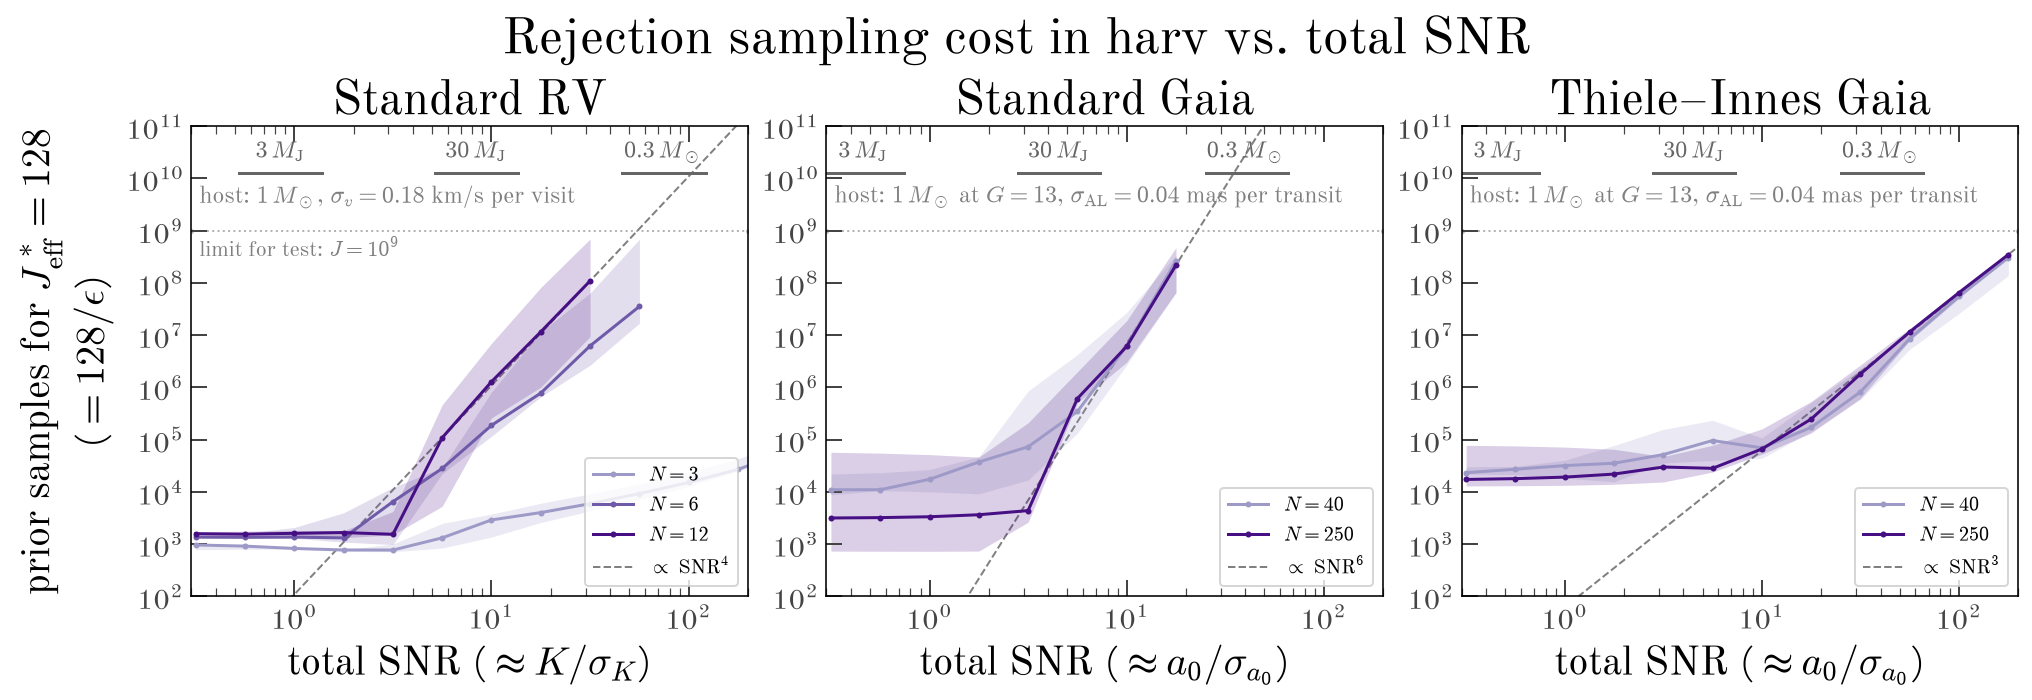

In [18]:
titles = {"rv": "Standard RV", "gaia": "Standard Gaia", "gaia_ti": "Thiele–Innes Gaia"}
xlabels = {
    "rv": r"total SNR ($\approx K/\sigma_K$)",
    "gaia": r"total SNR ($\approx a_0/\sigma_{a_0}$)",
    "gaia_ti": r"total SNR ($\approx a_0/\sigma_{a_0}$)",
}
host_labels = {
    "rv": rf"host: ${HOST_MASS.value:g}\,M_\odot$, "
    rf"$\sigma_v = {SIGMA['rv']}$ km/s per visit",
    "gaia": rf"host: ${HOST_MASS.value:g}\,M_\odot$ at $G = {G_HOST:g}$, "
    # "\n"
    rf"$\sigma_{{\rm AL}} = {SIGMA['gaia']}$ mas per transit",
}
host_labels["gaia_ti"] = host_labels["gaia"]
rho_grid = np.geomspace(0.3, 200, 64)
# A resolved cell has J_eff >= ESS_MIN with J <= J_MAX, so no cell can show more than:
J_LIMIT = X * J_MAX / ESS_MIN

# The right axis converts prior samples to time on one device, using R(N) at the
# largest N. The other N differ by these factors:
device = "1 GPU" if "1 GPU" in device_names else "1 CPU core"
n_axis = {kind: n[-1] for kind, n in N_VALUES.items()}
for kind in KINDS:
    for n_obs in N_VALUES[kind]:
        R = throughput[device, kind, n_obs]
        msg = f"{kind}, N = {n_obs}: R / R(N = {n_axis[kind]}) = "
        msg += f"{R / throughput[device, kind, n_axis[kind]]:.2f}"
        if device != "1 CPU core":
            R_cpu = throughput["1 CPU core", kind, n_obs]
            msg += f", {device} / 1 CPU core = {R / R_cpu:.0f}"
        print(msg)

fig, axes = plt.subplots(
    1, len(KINDS), figsize=(14, 4.75), sharex=True, sharey=True, layout="constrained"
)
for i, (ax, kind) in enumerate(zip(axes, KINDS, strict=True)):
    ax.set(xscale="log", yscale="log", xlim=(0.3, 200), ylim=(1e2, 1e11))
    ax.set(title=titles[kind], xlabel=xlabels[kind])

    # Shades of one hue, light to dark with N. (Blue and green mean CPU and GPU in the
    # figure from benchmarks-thejoker.ipynb.)
    colors = plt.cm.Purples(np.linspace(0.5, 0.95, len(N_VALUES[kind])))
    for color, n_obs in zip(colors, N_VALUES[kind], strict=True):
        rhos, need = sweep_curve(kind, n_obs)
        ax.fill_between(
            rhos, need.min(axis=1), need.max(axis=1), color=color, alpha=0.2, lw=0
        )
        ax.plot(
            rhos,
            np.median(need, axis=1),
            marker="o",
            ms=3,
            color=color,
            label=f"$N = {n_obs}$",
        )
        if n_obs == n_axis[kind]:
            expp = D_NL[kind]
            guide = np.median(need[-1]) * (rho_grid / rhos[-1]) ** expp

    ax.plot(
        rho_grid,
        guide,
        color="0.5",
        ls="--",
        lw=1,
        marker="",
        zorder=-1,
        label=r"$\propto$ SNR$^" + f"{expp}$",
    )
    ax.axhline(J_LIMIT, color="0.7", lw=1, zorder=-2, ls=":")

    if i == 0:
        ax.text(
            0.33,
            J_LIMIT / 1.3,
            rf"limit for test: $J = 10^{{{np.log10(J_MAX):.0f}}}$",  # , $J_{{\rm eff}} = {ESS_MIN}$",
            fontsize=11,
            color="0.5",
            va="top",
        )

    # The total SNR of the representative companions, over the values of N:
    for name, (_, label) in COMPANIONS.items():
        rho = companion_rho[kind, name]
        ax.plot(
            [rho.min(), rho.max()],
            [0.9, 0.9],
            color="0.4",
            lw=1.5,
            marker="|",
            ms=6,
            transform=ax.get_xaxis_transform(),
        )
        ax.text(
            np.sqrt(rho.min() * rho.max()),
            0.92,
            label,
            color="0.4",
            ha="center",
            va="bottom",
            fontsize=12,
            transform=ax.get_xaxis_transform(),
        )
    # The assumptions that set where the bars sit:
    ax.text(
        0.33,
        0.875,
        host_labels[kind],
        va="top",
        fontsize=12,
        color="0.5",
        transform=ax.get_xaxis_transform(),
    )

    ax.legend(loc="lower right", fontsize=10)
    R = throughput[device, kind, n_axis[kind]]
    ax.yaxis.set_ticks_position("left")
    # sec = ax.secondary_yaxis(
    #     "right", functions=(lambda J, R=R: J / R, lambda t, R=R: t * R)
    # )
    # sec.set_yticks([1e-3, 1, 60, 3600], labels=["1 ms", "1 s", "1 min", "1 hr"])
    # sec.yaxis.set_minor_locator(plt.NullLocator())

axes[0].set_ylabel(
    rf"prior samples for $J_{{\rm eff}}^* = {X}$" + "\n" + rf"($= {X} / \epsilon$)"
)
axes[0].set_yticks(10 ** np.arange(2, 11 + 1, 1))
# sec.set_ylabel(f"time on {device}")
fig.suptitle("Rejection sampling cost in harv vs. total SNR", fontsize=26)
fig.savefig(figure_path / "bench-ess.pdf")